# <div style="background-color:rgba(255, 255, 255, 0.1); text-align:center; vertical-align: middle; padding:40px 0; margin-top:30px"><span style="color:rgba(0, 0, 0, 1);"> Split-Ring Resonator Lab</span></span></div>

In [1]:
# Hide unnecessary warnings.
import warnings
warnings.filterwarnings('ignore')

# Import PHYS231.py and then run the installer function.
import PHYS231
PHYS231.Installer()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm # used to generate a sequence of colours for plotting
import pandas as pd
import scipy.stats as sp
from scipy.optimize import curve_fit
from IPython.display import HTML as html_print
from IPython.display import display, Markdown, Latex
import uncertainties
import math
import sys
from uncertainties import ufloat, correlated_values

## Constants and geometry

In [3]:
c = 2.998e8
mu0 = 4e-7*np.pi
eps0 = 8.854e-12
rho = 2.8e-8  # Al, errata value

# SRR dimensions in m, swap in measured values
r0 = 1.746e-2
ell = 10.16e-2
g_w = 0.794e-2
g_t = 0.254e-3

M_NaCl = 58.44  # g/mol
V_tank = 28.1  # L
err_V_tank = 1.2
err_m = 0.01  # g
err_dBm = 0.1

## Data

In [40]:
# f in MHz, P in dBm


f_air = np.loadtxt('Air_NS_R2.csv', delimiter=',', usecols=0, skiprows=1)
P_air = np.loadtxt('Air_NS_R2.csv', delimiter=',', usecols=1, skiprows=1)

f_shield = np.loadtxt('Air_S_R3.csv', delimiter=',', usecols=0, skiprows=1)
P_shield = np.loadtxt('Air_S_R3.csv', delimiter=',', usecols=1, skiprows=1)

f_water = np.loadtxt('Still_Water_S_R2.csv', delimiter=',', usecols=0, skiprows=1)
P_water = np.loadtxt('Still_Water_S_R2.csv', delimiter=',', usecols=1, skiprows=1)

# total NaCl in the tank (g), one sweep per entry
m_NaCl = np.array([0, 0.005, 0.010, 0.020, 0.030, 0.040, 0.060, 0.100, 0.150, 0.200,
                   0.400, 0.600, 0.800, 1.20, 1.60, 2.00, 2.50, 3.50, 5.00])
f_salt = [np.array([]) for _ in m_NaCl]
P_salt = [np.array([]) for _ in m_NaCl]

## Fitting

In [41]:
def dbm_to_v(P, eP):
    V = np.sqrt(10**(P/10)) # Converts to mW and turns into Voltage from squareroot
    return V, V*np.log(10)/20*eP # Gives error of voltage


def lorentz(f, A, f0, G):
    # f in MHz, G in 1e6 rad/s
    return A/np.sqrt(1 + (2*np.pi*f/G)**2*(1 - (f0/f)**2)**2) # From equation 7 in Jake's Paper


def fit_resonance(f, P, half_window_MHz=2.5):
    i = np.argsort(f); f, P = f[i], P[i]
    V = 10**(P/20)                                   # same as dbm_to_v
    fm = f/1e6                                       # MHz inside the fit
    Vs = np.convolve(V, np.ones(9)/9, mode='same')   # ignore single-point spikes
    k = np.argmax(Vs[10:-10]) + 10
    m = np.abs(fm - fm[k]) < half_window_MHz

    def model(x, A, f0, Q, c):
        return A/np.sqrt(1 + (Q*x/f0)**2*(1 - (f0/x)**2)**2) + c

    lo = [0,         fm[k]-1, 20,   -0.2*Vs[k]]
    hi = [3*Vs[k],   fm[k]+1, 5000,  0.2*Vs[k]]
    p, cov = curve_fit(model, fm[m], V[m], p0=[Vs[k], fm[k], 300, 0],
                       bounds=(lo, hi), maxfev=20000)
    A, f0, Q = correlated_values(p[:3], cov[:3, :3])
    c = p[3]
    G = 2*np.pi*p[1]*1e6/p[2]                        # rad/s, matches old lorentz(f in Hz)
    popt = [p[0], p[1]*1e6, G]                       # works with the old lorentz() and plot_sweep
    return f0*1e6, Q, popt, V - c                    # f0 in Hz, offset removed


def plot_sweep(ax, f, P, off=0, label=None):
    f0, Q, popt, V = fit_resonance(f, P)
    fs = np.linspace(f.min(), f.max(), 400)
    ax.plot(np.sort(f), V[np.argsort(f)]/popt[0] + off, "o", ms=4, label=label)
    ax.plot(fs, lorentz(fs, *popt)/popt[0] + off, "k-", lw=1)

In [42]:
runs = {"air": (f_air, P_air), "shield": (f_shield, P_shield), "water": (f_water, P_water)}
res = {name: fit_resonance(f, P)[:2] for name, (f, P) in runs.items() if f.size}

# paper values used until your own data is in
paper = {"air": (ufloat(353.10, 0.03), ufloat(244, 5)),
         "shield": (ufloat(355.487, 0.005), ufloat(2050, 20)),
         "water": (ufloat(40.174, 0.005), ufloat(159, 3))}


def get(name):
    return res.get(name, res[name])


for name in res:
    f0, Q = get(name)
    Sd=((2*rho)/(mu0*f0*2*np.pi))**0.5
    Q_p= r0/Sd
    f0_MHz = f0/1000000
    print(f"{name:7s} f0 = {f0_MHz:.3f} MHz   Q = {Q:.0f}   Q_Pred = {Q_p}") 

#Sd=((2*rho)/(mu0*f0*2*np.pi))**0.5
#Q_p= r0/Sd

#print("Q_p", Q_p)

air     f0 = 327.843+/-0.004 MHz   Q = 149+/-2   Q_Pred = 3144.638+/-0.018
shield  f0 = 331.105+/-0.000 MHz   Q = 302+/-0   Q_Pred = 3160.2410+/-0.0008
water   f0 = 49.212+/-0.001 MHz   Q = 71+/-0   Q_Pred = 1218.358+/-0.015


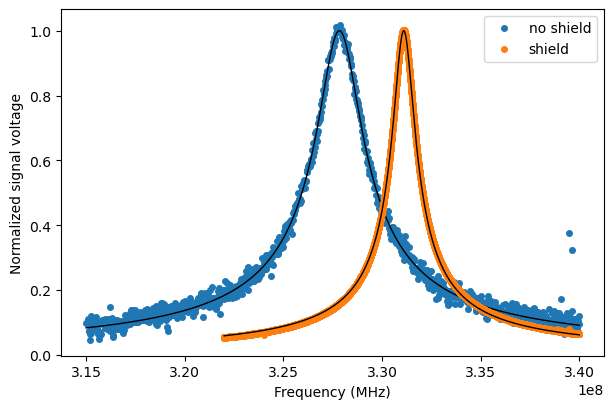

In [43]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f, P in [("no shield", f_air, P_air), ("shield", f_shield, P_shield)]:
    if f.size:
        plot_sweep(ax, f, P, label=name)
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Normalized signal voltage")
ax.legend()
plt.show()

## Circuit model predictions

In [44]:
L = mu0*np.pi*r0**2/ell
C = eps0*g_w*ell/g_t
om_pred = (L*C)**-0.5
delta = lambda om: (2*rho/(mu0*om))**0.5
R_delta = lambda om: rho*2*np.pi*r0/(delta(om)*ell)

f_s, Q_s = get("shield")
print(f"f0 predicted = {om_pred/2/np.pi/1e6:.1f} MHz")
print(f"Q predicted (at predicted f0) = {r0/delta(om_pred):.0f}")
print(f"Q predicted (at measured f0)  = {r0/delta(2*np.pi*f_s.n*1e6):.0f}")

f0 predicted = 275.8 MHz
Q predicted (at predicted f0) = 2884
Q predicted (at measured f0)  = 3160241


## Water

In [45]:
f_H2O, Q_H2O = get("water")
om_s = 2*np.pi*f_s*1e6
om_w = 2*np.pi*f_H2O*1e6

eps_r = (f_s/f_H2O)**2

R_tot = om_s*L/Q_s
R_ex = R_tot - R_delta(om_s)
Q_d = r0/delta(om_w)
Q_ex = om_w*L/R_ex
Q_eps = 1/(1/Q_H2O - 1/Q_d - 1/Q_ex)
eps_i = eps_r/Q_eps

print(f"eps' = {eps_r:.2f}")
print(f"R_tot = {R_tot*1e3:.1f} mOhm,  R_ex = {R_ex*1e3:.1f} mOhm")
print(f"Q_d = {Q_d:.0f},  Q_ex = {Q_ex:.0f},  Q_eps'' = {Q_eps:.0f}")
print(f"eps'' = {eps_i:.2f}")

eps' = 45.27+/-0.00
R_tot = 81604295.0+/-59400.9 mOhm,  R_ex = 81596497.1+/-59400.9 mOhm
Q_d = 1218358+/-15,  Q_ex = 45+/-0,  Q_eps'' = -122+/-1
eps'' = -0.37+/-0.00


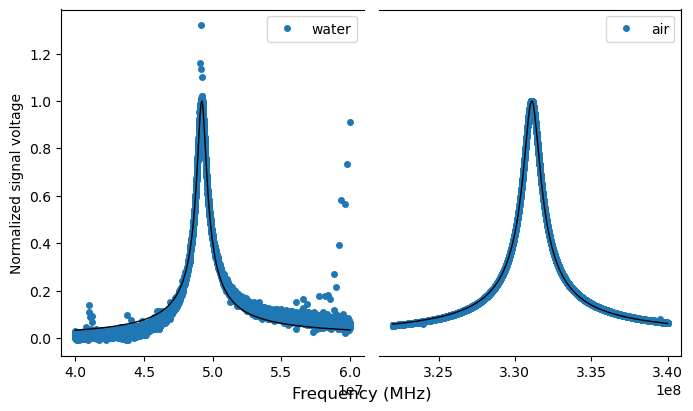

In [46]:
fig, (a1, a2) = plt.subplots(1, 2, sharey=True, figsize=(8, 4.5), gridspec_kw={"wspace": 0.05})
if f_water.size:
    plot_sweep(a1, f_water, P_water, label="water")
if f_shield.size:
    plot_sweep(a2, f_shield, P_shield, label="air")
a1.spines["right"].set_visible(False)
a2.spines["left"].set_visible(False)
a2.tick_params(left=False)
a1.set_ylabel("Normalized signal voltage")
fig.supxlabel("Frequency (MHz)")
a1.legend()
a2.legend()
plt.show()

## Salt series

In [11]:
sigma = 10.394*(m_NaCl/M_NaCl)/V_tank
err_sigma = 10.394/M_NaCl/V_tank*np.sqrt(err_m**2 + (m_NaCl*err_V_tank/V_tank)**2)

Q_net = np.full(len(m_NaCl), np.nan)
err_Q_net = np.full(len(m_NaCl), np.nan)
f_net = np.full(len(m_NaCl), np.nan)
for i, (f, P) in enumerate(zip(f_salt, P_salt)):
    if f.size:
        f0, Q = fit_resonance(f, P)[:2]
        f_net[i], Q_net[i], err_Q_net[i] = f0.n, Q.n, Q.s

# Table I from the paper until your sweeps are in
if np.all(np.isnan(Q_net)):
    Q_net = np.array([159, 180, 172, 158, 134, 110, 87, 79, 69, 55, 53, 25.2, 20.0, 18.9, 12.0, 12.9, 10.0, 8.4, 7.8])
    err_Q_net = np.array([3, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1, 0.5, 0.5, 0.4, 0.3, 0.3, 0.3, 0.3, 0.3])

ok = (sigma > 0) & ~np.isnan(Q_net)

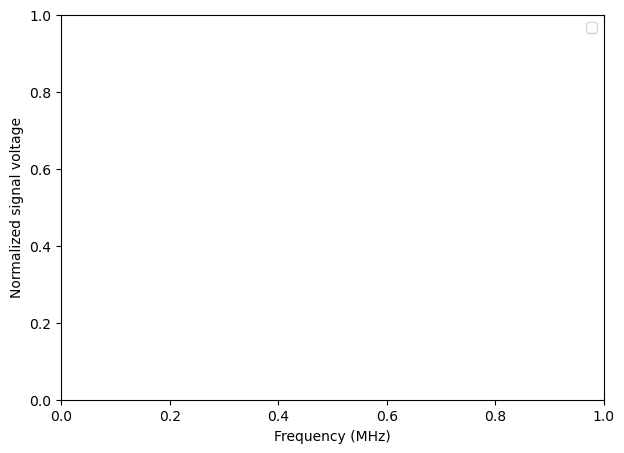

In [12]:
show = [1, 6, 12, 15]
fig, ax = plt.subplots(figsize=(7, 5))
for k, i in enumerate(show):
    if f_salt[i].size:
        plot_sweep(ax, f_salt[i], P_salt[i], off=0.75*k, label=f"{sigma[i]:.1e} S/m")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Normalized signal voltage")
ax.legend()
plt.show()

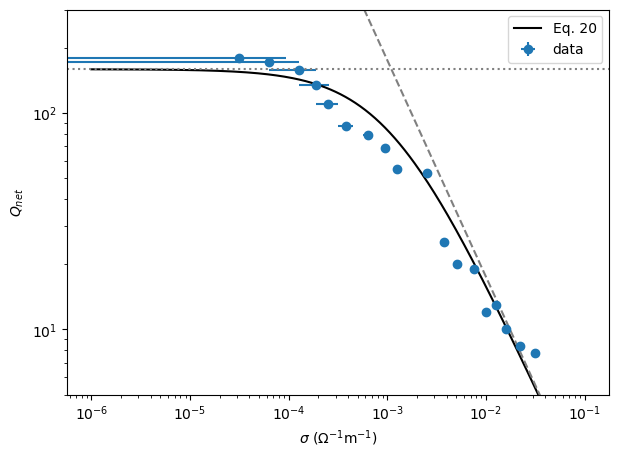

In [13]:
s = np.logspace(-6, -1, 300)
Q_mod = 1/(1/Q_H2O.n + s/(om_w.n*eps_r.n*eps0))

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(sigma[ok], Q_net[ok], xerr=err_sigma[ok], yerr=err_Q_net[ok], fmt="o", label="data")
ax.plot(s, Q_mod, "k-", label="Eq. 20")
ax.axhline(Q_H2O.n, ls=":", c="gray")
ax.plot(s, om_w.n*eps_r.n*eps0/s, "--", c="gray")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(5, 300)
ax.set_xlabel(r"σ\sigmaσ (Ω−1\Omega^{-1}Ω−1m−1^{-1}−1)")
ax.set_ylabel(r"QnetQ_{net}Qnet​")
ax.legend()
plt.show()

In [14]:
def Q_fit(s, Q0, e):
    return 1/(1/Q0 + s/(om_w.n*e*eps0))


popt, pcov = curve_fit(Q_fit, sigma[ok], Q_net[ok], p0=[Q_H2O.n, eps_r.n], sigma=err_Q_net[ok])
print(f"Q0 = {popt[0]:.0f} +/- {np.sqrt(pcov[0, 0]):.0f}")
print(f"eps' = {popt[1]:.1f} +/- {np.sqrt(pcov[1, 1]):.1f}")

sig_c = om_w.n*eps_r.n*eps0/Q_H2O.n
print(f"plateau ends near sigma = {sig_c:.1e}, model valid below 0.2")

Q0 = 150 +/- 12
eps' = 59.2 +/- 5.9
plateau ends near sigma = 1.1e-03, model valid below 0.2


## Helpers

In [ ]:
from IPython.display import HTML, display


def variable_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 15px; border-radius: 8px; font-family: sans-serif; max-width: 520px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        <div style="margin-bottom: 10px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Variable Name(s) (comma-separated):</label>
            <input type="text" id="var_names_input" placeholder="e.g. theta_m, I, B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <div style="margin-bottom: 14px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Units / Comment (Optional, comma-separated):</label>
            <input type="text" id="units_comment_input" placeholder="e.g. deg, A, T" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <button id="copy_btn" onclick="copyAndReset()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Template & Reset
        </button>
    </div>

    <script>
    function copyAndReset() {
        const varInput = document.getElementById('var_names_input');
        const commentInput = document.getElementById('units_comment_input');
        const btn = document.getElementById('copy_btn');
        
        const vars = varInput.value.split(',').map(s => s.trim()).filter(s => s.length > 0);
        const comments = commentInput.value.split(',').map(s => s.trim());
        
        if (vars.length === 0) {
            btn.innerText = 'Please enter at least one variable name!';
            btn.style.backgroundColor = '#d73a49';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
            return;
        }
        
        let lines = [];
        vars.forEach((v, idx) => {
            let comment = comments[idx] !== undefined ? comments[idx] : (comments[0] || '');
            let commentStr = comment ? `  # ${comment}` : '';
            lines.push(`${v} = np.array([])${commentStr}`);
            lines.push(`err_${v} = np.full_like(${v}, 0.0)\\n`);
        });
        
        const fullCode = lines.join('\\n').trim();
        
        navigator.clipboard.writeText(fullCode).then(() => {
            btn.innerText = 'Copied to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            varInput.value = '';
            commentInput.value = '';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


# Run to render the interactive widget block
variable_template_builder()

In [ ]:
from IPython.display import HTML, display


def graph_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 18px; border-radius: 8px; font-family: sans-serif; max-width: 540px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        
        <div style="margin-bottom: 12px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Graph / Analysis Type:</label>
            <select id="graph_type" onchange="updateFields()" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; font-family: sans-serif;">
                <option value="LinearFit">Linear Fit (PHYS231.LinearFit)</option>
                <option value="Scatter">Scatter Plot (PHYS231.Scatter)</option>
                <option value="PowerLaw">Power Law Fit (PHYS231.PowerLaw)</option>
                <option value="Charging">RC Charging Fit (PHYS231.Charging)</option>
                <option value="Sine">Sine Wave Fit (PHYS231.Sine)</option>
                <option value="Braking">Magnetic Braking Fit (PHYS231.Braking)</option>
                <option value="Statistics">Histogram & Stats (PHYS231.Statistics)</option>
            </select>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div id="box_xData">
                <label id="lbl_xData" style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Data Variable:</label>
                <input type="text" id="xData_input" placeholder="e.g. I" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yData">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Data Variable:</label>
                <input type="text" id="yData_input" placeholder="e.g. B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 10px;" id="box_yErrors">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Errors Variable:</label>
            <input type="text" id="yErrors_input" placeholder="e.g. err_B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Axis Label:</label>
                <input type="text" id="xlabel_input" placeholder="e.g. Current" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_ylabel">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Axis Label:</label>
                <input type="text" id="ylabel_input" placeholder="e.g. Magnetic Field" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 12px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Units:</label>
                <input type="text" id="xUnits_input" placeholder="e.g. A" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yUnits">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Units:</label>
                <input type="text" id="yUnits_input" placeholder="e.g. mT" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 14px; display: none;" id="box_nbins">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Number of Bins:</label>
            <input type="text" id="nbins_input" placeholder="10" value="10" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <button id="graph_copy_btn" onclick="copyAndResetGraph()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Graph Code & Reset
        </button>
    </div>

    <script>
    function updateFields() {
        const type = document.getElementById('graph_type').value;
        const isStats = (type === 'Statistics');

        document.getElementById('box_yData').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yErrors').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_ylabel').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yUnits').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_nbins').style.display = isStats ? 'block' : 'none';

        document.getElementById('lbl_xData').innerText = isStats ? 'Data Variable:' : 'X Data Variable:';
    }

    function copyAndResetGraph() {
        const type = document.getElementById('graph_type').value;
        const xData = document.getElementById('xData_input').value.trim() || 'x_data';
        const yData = document.getElementById('yData_input').value.trim() || 'y_data';
        const yErrors = document.getElementById('yErrors_input').value.trim() || 'err_y_data';
        const xlabel = document.getElementById('xlabel_input').value.trim();
        const ylabel = document.getElementById('ylabel_input').value.trim();
        const xUnits = document.getElementById('xUnits_input').value.trim();
        const yUnits = document.getElementById('yUnits_input').value.trim();
        const nbins = document.getElementById('nbins_input').value.trim() || '10';

        let code = '';

        if (type === 'LinearFit') {
            code = `slope, intercept, err_slope, err_intercept, fig = PHYS231.LinearFit(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False\\n)`;
        } else if (type === 'Scatter') {
            code = `fig = PHYS231.Scatter(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False,\\n    show=True\\n)`;
        } else if (type === 'PowerLaw') {
            code = `coeff, power, offset, errA, errN, errC, fig = PHYS231.PowerLaw(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Charging') {
            code = `A, tau, errA, errTau, fig = PHYS231.Charging(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Sine') {
            code = `amp, period, phase, errA, errT, errPhi, fig = PHYS231.Sine(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Braking') {
            code = `v_term, tau, err_v, err_tau, fig = PHYS231.Braking(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Statistics') {
            code = `counts, centres, mean, std_dev, std_err, fig = PHYS231.Statistics(\\n    data=${xData},\\n    nbins=${nbins},\\n    xlabel="${xlabel}",\\n    xUnits="${xUnits}",\\n    normalized=False\\n)`;
        }

        const btn = document.getElementById('graph_copy_btn');

        navigator.clipboard.writeText(code).then(() => {
            btn.innerText = 'Copied Code to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            
            // Clear input fields
            document.getElementById('xData_input').value = '';
            document.getElementById('yData_input').value = '';
            document.getElementById('yErrors_input').value = '';
            document.getElementById('xlabel_input').value = '';
            document.getElementById('ylabel_input').value = '';
            document.getElementById('xUnits_input').value = '';
            document.getElementById('yUnits_input').value = '';
            
            setTimeout(() => { 
                btn.innerText = 'Copy Graph Code & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


graph_template_builder()

# SRR Lab: Hints and Tricks

## Goal for 3 hours
- Minimum: shielded air + water sweeps -> f0, Q, eps' (~78.3)
- Good: + unshielded air sweep, eps'' from loss budget
- Stretch: 3-4 salt points (full series needs 1 h settling each, so skip it)

## Connections
- Loop A -> signal generator (drives SRR)
- Loop B -> spectrum analyzer / detector (measures response)
- Generator output ~ -35 dBm
- Loops ~1 in from the ends of the SRR
- Keep coupling weak so loaded Q ~ unloaded Q

## Before measuring
- Remove the SRR and sweep: no loop-to-loop signal should show up
- Change generator power: resonance shape should not change
- Measure and record r0, length, gap w, gap t (t is hard to measure, so expect predicted f0 to be off)
- Keep thermometers/heater wires out of the enclosure (lambda/4 resonances)
- Watch for a broad resonance that shifts when coupling moves = coax lambda/4 problem

## Shielding
- Closed conducting tube, circumference < c/f0 (below TE11 cutoff)
- Paper: plastic pipe, 214 mm OD, 97 cm long, 4-5 layers of Al foil, taped
- Tube must extend well past the SRR ends
- SRR cross-section should be much smaller than the tube
- Unshielded: hand wave shifts the resonance (radiation losses)

## Expected values (paper)
- Air, no shield: f0 ~ 353.1 MHz, Q ~ 244
- Air, shielded: f0 ~ 355.5 MHz, Q ~ 2050
- Water: f0 ~ 40.17 MHz, Q ~ 159, eps' ~ 78.30
- Your numbers will differ with your own geometry

## Sweep tips
- Find the peak with a wide sweep first, then zoom
- Shielded air: FWHM ~ 0.17 MHz -> span ~1 MHz, ~20 pts, dense near peak
- Water: FWHM ~ 0.25 MHz
- Record: freq, dBm, generator power, analyzer span + RBW, loop positions
- Convert dBm -> voltage before fitting: V = sqrt(10^(P/10))

## Water
- Fill, then sway SRR by its rods for 2-3 min to remove air bubbles
- Bubbles ruin eps' measurement
- Ask first if the tank can be pre-filled
- Log water temp and volume (paper: 28.1 +/- 1.2 L)

## Salt (stretch)
- Pick masses spread across the range, e.g. 0.02, 0.2, 1.2, 5.0 g
- Dissolve in ~500 mL of tank water, pour back in, stir
- Watch the lineshape until it stops changing; note actual wait time
- Log total NaCl mass in tank (+/- 0.01 g)

## Key equations
- L = mu0*pi*r0^2 / ell
- C = eps0*w*ell / t
- f0 = (1/2pi) * 1/sqrt(LC)
- skin depth delta = sqrt(2*rho / (mu0*omega))
- Q = r0 / delta (no radiation)
- Lorentzian (errata form): V = 1 / sqrt(1 + (2*pi*f/G)^2 * (1 - (f0/f)^2)^2), Q = omega0/G
- eps' = (f0_air / f_water)^2
- 1/Q_water = 1/Q_delta + 1/Q_ex + 1/Q_eps''
- eps'' = eps' / Q_eps''
- sigma = 10.394 * N (N in mol/L, 25 C), N = (mass/58.44) / volume
- 1/Q_net = 1/Q_water + sigma / (omega * eps' * eps0)

## Gotchas
- Errata: rho_Al = 2.8e-8 ohm*m (paper says 8.2e-8, wrong)
- Errata: Eq. 7 needs the [ ]^2 on the bracket (see formula above)
- Low-conductivity model valid for sigma << 0.2 S/m
- f0 doesn't move with salt; only Q drops
- Salt: Q flat at low sigma, then ~1/sigma at high sigma

## Notebook
- SRR_Lab.ipynb: paste arrays into f_air/P_air, f_shield/P_shield, f_water/P_water
- Salt: f_salt[i] = np.array([...]), P_salt[i] = np.array([...])
- Uses paper values until your data is entered
- Run it right after the air sweep to catch bad data early

## Before leaving the lab
- Geometry, water temp, tank volume recorded
- All sweep data saved (files + photo of screen)
- Settling times for salt points noted

# TESTING


f0 = 331.099 MHz   loaded Q = 269.3   FWHM = 1.23 MHz
S11 / baseline: 852 baseline points of 999
S22 / baseline: 852 baseline points of 999
S11 dip = -0.057 dB  beta1 = 0.0033
S22 dip = -5.850 dB  beta2 = 0.3246
unloaded Q = 357.6  (32.8% above loaded Q)


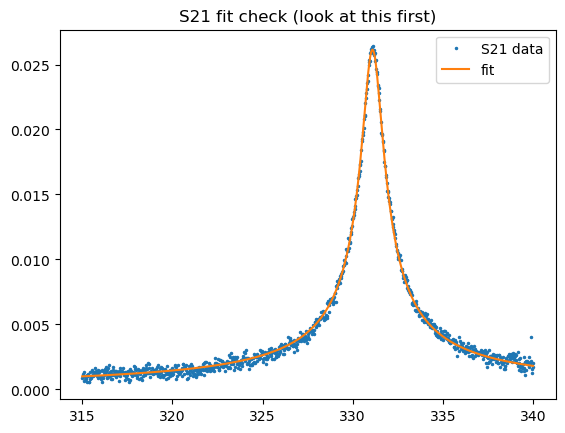

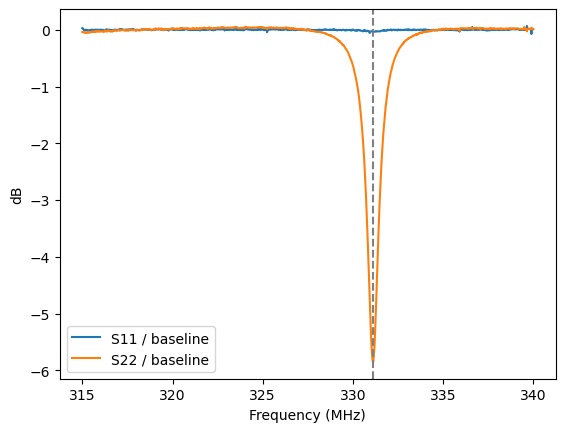

In [24]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# ---------- YOUR DATA GOES HERE ----------
freq = np.loadtxt('S11_S21_S22_R3.csv', delimiter=',', usecols=0, skiprows=1)   # Hz
S11  = np.loadtxt('S11_S21_S22_R3.csv', delimiter=',', usecols=1, skiprows=1)
S21  = np.loadtxt('S11_S21_S22_R3.csv', delimiter=',', usecols=2, skiprows=1)
S22  = np.loadtxt('S11_S21_S22_R3.csv', delimiter=',', usecols=3, skiprows=1)
# -----------------------------------------

f = freq / 1e6                                           # MHz

# dB -> linear amplitude (skip if your file is already linear)
def to_lin(x):
    return 10**(x/20) if np.median(x) < 0 else np.abs(x)
m11, m21, m22 = to_lin(S11), to_lin(S21), to_lin(S22)

# ---------- 1. S21: fit f0 and loaded Q ----------
def lorentz(f, A, f0, Q, c):
    return A / np.sqrt(1 + (2*Q*(f/f0 - 1))**2) + c

fpk = f[m21.argmax()]
p0  = [m21.max(), fpk, 100, 0]
lo  = [0, fpk - 3, 5, 0]
hi  = [m21.max()*2, fpk + 3, 5000, m21.max()]
(A, f0, QL, c), _ = curve_fit(lorentz, f, m21, p0=p0, bounds=(lo, hi))
fwhm = f0 / QL
print(f"f0 = {f0:.3f} MHz   loaded Q = {QL:.1f}   FWHM = {fwhm:.2f} MHz")

plt.figure()
plt.plot(f, m21, ".", ms=3, label="S21 data")
plt.plot(f, lorentz(f, A, f0, QL, c), label="fit")
plt.title("S21 fit check (look at this first)"); plt.legend()

# ---------- 2. S11 / S22: baseline removal (magnitude only) ----------
def beta_from(m, label, deg=2, mask_widths=1.5):
    mask = np.abs(f - f0) > mask_widths * fwhm           # baseline points
    print(f"{label}: {mask.sum()} baseline points of {len(f)}")
    if mask.sum() < 0.25*len(f):
        print(f"  WARNING: too little baseline for {label}. Re-sweep a wider span.")
    base  = np.polyval(np.polyfit(f[mask], m[mask], deg), f)
    resid = m / base
    gamma = resid[~mask].min()                           # dip depth near resonance
    beta  = (1 - gamma) / (1 + gamma)
    plt.figure(2)
    plt.plot(f, 20*np.log10(resid), label=label)
    return beta, gamma

b1, g1 = beta_from(m11, "S11 / baseline")
b2, g2 = beta_from(m22, "S22 / baseline")
print(f"S11 dip = {20*np.log10(g1):.3f} dB  beta1 = {b1:.4f}")
print(f"S22 dip = {20*np.log10(g2):.3f} dB  beta2 = {b2:.4f}")

# ---------- 3. Unloaded Q ----------
Q0 = QL * (1 + b1 + b2)
print(f"unloaded Q = {Q0:.1f}  ({100*(Q0/QL - 1):.1f}% above loaded Q)")

plt.figure(2)
plt.axvline(f0, ls="--", c="gray")
plt.xlabel("Frequency (MHz)"); plt.ylabel("dB"); plt.legend()
plt.show()

In [25]:
import numpy as np

# ---------- INPUTS (edit these) ----------
r0   = 1.746e-2        # m, inner radius of YOUR SRR (paper's value; change if yours differs)
rho  = 3.99e-8         # ohm*m. 6061 Al ~3.99e-8, pure Al ~2.65e-8, paper's errata 2.8e-8, Cu 1.68e-8
shielded = True       # True applies the paper's ~2.2% shield correction
# -----------------------------------------

mu0 = 4e-7*np.pi
w0  = 2*np.pi*f0*1e6                       # f0 is in MHz from the earlier script

delta   = np.sqrt(2*rho/(mu0*w0))          # skin depth (m)
Q_delta = r0/delta                         # Eq. 6
if shielded:
    Q_delta *= 1.022

# Everything Eq. 6 doesn't include: 1/Q0 = 1/Q_delta + 1/Q_other
inv_other = 1/Q0 - 1/Q_delta
Q_other   = 1/inv_other if inv_other > 0 else np.inf

print(f"skin depth        = {delta*1e6:.2f} um")
print(f"Q_delta (Eq. 6)   = {Q_delta:.0f}")
print(f"Q0 measured       = {Q0:.0f}   (Q_L = {QL:.0f})")
print(f"Q0 / Q_delta      = {Q0/Q_delta:.2f}")
print(f"Q_other (rad + joint + nearby loss) = {Q_other:.0f}")
print(f"fraction of loss from skin effect   = {100*(1/Q_delta)/(1/Q0):.1f}%")

# Sensitivity to the resistivity choice
for name, r in [("pure Al (errata)", 2.8e-8), ("6061 Al", 3.99e-8), ("paper's wrong value", 8.2e-8)]:
    d = np.sqrt(2*r/(mu0*w0))
    print(f"  {name:20s} Q_delta = {r0/d:.0f}")

skin depth        = 5.52 um
Q_delta (Eq. 6)   = 3230
Q0 measured       = 358   (Q_L = 269)
Q0 / Q_delta      = 0.11
Q_other (rad + joint + nearby loss) = 402
fraction of loss from skin effect   = 11.1%
  pure Al (errata)     Q_delta = 3772
  6061 Al              Q_delta = 3160
  paper's wrong value  Q_delta = 2204
